# Проект: Прогнозирование стоимости недвижимости
## Общая постановка задачи
Постройте и протестируйте несколько моделей регрессии для прогнозирования цен объекта
недвижимости на основе его характеристики, а также разработайте приложение с формой
входных данных, дашбордом и справочной информацией.

# Этап 1. Исследование данных (EDA)

## 1.1 Знакомство с данными
* Загрузить набор дат, вывести размерность (число строк/столбцов), определить
данные по столбцам.
* Выведите первые/последние строки, выберите случайную строку.
* Описать источник данных, получить критерии измерения, определить целевую
переменную (цену).

In [1]:
import pandas as pd
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import KFold, train_test_split, RandomizedSearchCV

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

import joblib
import os

In [2]:
zingat = pd.read_csv('real_estate_data.csv', low_memory=False)
zingat.info()

<class 'pandas.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  str    
 2   sub_type           403487 non-null  str    
 3   start_date         403487 non-null  str    
 4   end_date           266298 non-null  str    
 5   listing_type       403487 non-null  int64  
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  str    
 8   total_floor_count  375466 non-null  str    
 9   floor_no           368191 non-null  str    
 10  room_count         403487 non-null  str    
 11  size               257481 non-null  float64
 12  address            403487 non-null  str    
 13  furnished          0 non-null       float64
 14  heating_type       375517 non-null  str    
 15  price              402772 non-null  float64
 16  price_currenc

In [3]:
pd.concat([zingat.head(3), zingat.sample(1), zingat.tail(3)])

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,1,Konut,Rezidans,12/10/18,1/9/19,2,30,0,20 ve üzeri,2,2+1,90.00,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,3500.00,TRY
1,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.00,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.00,TRY
2,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.00,TRY
390485,390486,Konut,Daire,2/21/19,NaN,2,6,NaN,NaN,NaN,3+1,140.00,Burdur/Merkez/Emek,NaN,NaN,1100.00,TRY
403484,403485,Konut,Daire,11/22/18,NaN,1,97,NaN,NaN,NaN,1+1,NaN,Antalya/Alanya/Saray,NaN,NaN,48000.00,EUR
403485,403486,Konut,Daire,2/21/19,NaN,2,6,NaN,NaN,NaN,2+1,2.00,Aydın/Kuşadası/Türkmen,NaN,NaN,900.00,TRY
403486,403487,Konut,Daire,1/15/19,1/18/19,1,3,NaN,NaN,NaN,3+1,140.00,Kayseri/Melikgazi/Alpaslan,NaN,NaN,210000.00,TRY


### Описание данных:

* **`id`** — уникальный идентификатор объявления.
* **`type`** — тип недвижимости:
  * `Konut` — жилая недвижимость (жилье).
* **`sub_type`** — подтип недвижимости:
    * `Daire` — квартира (в обычном многоквартирном доме);
    * `Villa` — вилла (благоустроенный дом, как правило, с собственным участком/бассейном);
    * `Müstakil Ev` — частный / отдельно стоящий дом;
    * `Rezidans` — резиденция / апартаменты повышенной комфортности (в ЖК с консьерж-сервисом, охраной и инфраструктурой);
    * `Yazlık` — летний дом / дача (сезонное жильё, обычно в курортной зоне);
    * `Komple Bina` — здание целиком (жилое или многоквартирное здание, продающееся одним лотом);
    * `Prefabrik Ev` — сборный / каркасный / модульный дом (быстровозводимое жильё);
    * `Çiftlik Evi` — фермерский дом / загородная усадьба (дом на сельскохозяйственном участке);
    * `Köşk / Konak / Yalı` — исторический особняк / усадьба / ялы (традиционные турецкие особняки, в том числе исторические приморские резиденции на Босфоре);
    * `Yalı Dairesi` — квартира в прибрежном особняке (ялы) или на первой линии у воды;
    * `Kooperatif` — кооперативное жильё (пай в жилищно-строительном кооперативе);
    * `Loft` — лофт (жильё открытой планировки с высокими потолками).
* **`start_date`** — дата публикации объявления на платформе.
* **`end_date`** — дата снятия объявления с публикации.
* **`listing_type`** — тип сделки:
  * `1` (`Satılık`) — продажа;
  * `2` (`Kiralık`) — аренда;
  * `3` (`Günlük Kiralık`) — посуточная аренда.
* **`tom`** (*Time on Market*) — количество дней нахождения объявления на рынке.
* **`building_age`** — возраст здания (в годах):
  * `0` — новостройка (до 1 года);
  * числовые интервалы (например, `6-10 arası` — от 6 до 10 лет; *«arası»* переводится как *«между»*);
  * `40 ve üzeri` — 40 лет и старше.
* **`total_floor_count`** — общая этажность здания:
  * число этажей либо интервалы (например, `10-20 arası` — от 10 до 20 этажей, `20 ve üzeri` — 20 этажей и более).
* **`floor_no`** — этаж расположения объекта:
    * числовые значения (`1`–`19`) — конкретный номер этажа над уровнем земли;
    * `20 ve üzeri` — 20-й этаж и выше (высотные здания / небоскрёбы);
    * **Входные и околоземные уровни:**
      * `Zemin Kat` — первый этаж на уровне земли (ground floor / нулевой уровень);
      * `Giriş Katı` — входной этаж (уровень главного входа в здание, часто совпадает с *Zemin Kat*);
      * `Yüksek Giriş` — высокий первый этаж (бельэтаж, приподнят над уровнем земли/тротуара);
      * `Bahçe katı` — садовый этаж (этаж с прямым выходом в сад или придомовую территорию);
    * **Цокольные и подуровни (характерно для рельефа со склонами):**
      * `Kot 1`, `Kot 2`, `Kot 3`, `Kot 4` — этажи ниже уровня входа (-1, -2, -3, -4 этажи; из-за холмистого рельефа со стороны склона в них часто есть полноценные окна и террасы);
      * `Bodrum Kat` — подвальный этаж (классический подвал);
    * **Верхние уровни:**
      * `Çatı Katı` — мансардный этаж (подскатный этаж под крышей);
      * `Teras Kat` — террасный этаж (последний этаж с открытой террасой / пентхаус);
      * `En Üst Kat` — последний / самый верхний этаж здания;
    * **Особые категории:**
      * `Asma Kat` — антресольный этаж (полуэтаж / мезонин);
      * `Müstakil` — частный / отдельный дом (объект занимает весь отдельный дом, конкретный этаж квартиры не применим);
      * `Komple` — здание целиком (объект включает в себя все этажи здания).
* **`room_count`** — планировка / количество комнат:
  * формат `X+Y`, где `X` — количество спален, `Y` — количество гостиных (например, `2+1` — 2 спальни и 1 гостиная; `1+0` — студия).
* **`size`** — общая площадь объекта в квадратных метрах ($м^2$).
* **`address`** — адрес объекта в формате: `Город / Район / Микрорайон` (*City / County / District*), например `İstanbul/Kartal/Kordonboyu`.
* **`furnished`** — наличие мебели:
  * `Eşyalı` — с мебелью;
  * `Eşyasız` — без мебели;
  * `Sadece Beyaz Eşya` — только крупная бытовая техника;
  * `Sadece Mutfak` — только кухонный гарнитур.
* **`heating_type`** — тип системы отопления:
  * `Kombi (Doğalgaz)` — индивидуальный газовый котел;
  * `Kombi (Elektrikli)` — индивидуальный электрический котел;
  * `Kalorifer (Doğalgaz)` — центральное отопление (природный газ);
  * `Kalorifer (Kömür)` — центральное отопление (уголь);
  * `Kalorifer (Akaryakıt)` — центральное отопление (жидкое топливо);
  * `Merkezi Sistem` — центральная система;
  * `Merkezi Sistem (Isı Payı Ölçer)` — центральная система с распределителем/счетчиком тепла;
  * `Kat Kaloriferi` — поэтажное/квартирное водяное отопление;
  * `Yerden Isıtma` — теплый пол;
  * `Klima` — кондиционер;
  * `Soba (Doğalgaz)` — газовая печь;
  * `Soba (Kömür)` — угольная печь;
  * `Güneş Enerjisi` — солнечная энергия;
  * `Jeotermal` — геотермальное отопление;
  * `Fancoil` — система фанкойлов;
  * `Yok` — отопление отсутствует.
* **`price`** — стоимость объекта недвижимости (**целевая переменная** для моделирования).
* **`price_currency`** — валюта, в которой указана стоимость объекта (`price`):
  * `TRY` — турецкая лира (основная национальная валюта, подавляющее большинство объявлений);
  * `EUR` — евро (характерно для курортных зон, ориентированных на европейцев — Анталья, Аланья);
  * `GBP` — британский фунт стерлингов (традиционно популярен на эгейском побережье — Фетхие, Дидим, Бодрум);
  * `USD` — доллар США (часто используется иностранными инвесторами).

## 1.2 Описательная статистика
* Рассчитать базовые статистики для числовых признаков: мин, макс, среднее,
медиана, стандартное, квартили.
* Для категориальных признаков — частота категорий, количество уникальных
показателей.
* Проверяйте параметры переменных (цены): гистограмма, точность асимметрии
(асимметрии).

In [4]:
zingat.describe()

,id,listing_type,tom,size,furnished,price
count,403487.00,403487.00,403487.00,257481.00,0.00,402772.00
mean,201744.00,1.29,57.02,279.35,NaN,354641.66
std,116476.81,0.47,44.36,9429.20,NaN,4809502.70
min,1.00,1.00,0.00,1.00,NaN,-250.00
25%,100872.50,1.00,29.00,85.00,NaN,2500.00
50%,201744.00,1.00,40.00,110.00,NaN,199000.00
75%,302615.50,2.00,90.00,140.00,NaN,342000.00
max,403487.00,3.00,180.00,948235.00,NaN,2000000000.00


In [5]:
zingat.describe(include='str')

,type,sub_type,start_date,end_date,building_age,total_floor_count,floor_no,room_count,address,heating_type,price_currency
count,403487,403487,403487,266298,376097,375466,368191,403487,403487,375517,402772
unique,1,12,181,181,14,12,35,37,7842,16,4
top,Konut,Daire,10/11/18,12/19/18,0,4,2,3+1,Balıkesir/Edremit/Akçay,Kombi (Doğalgaz),TRY
freq,403487,354549,4064,3048,140174,83082,65864,157363,5611,204150,400677


Для облегчения датасета, я сразу уберу лишние признаки, которые или не нужны, или дублируют другие. Так же для корректности я переведу все цены на турецкие.

_Для унификации цен использованы средние фиксированные курсы за период выборки (сентябрь 2018 – февраль 2019): 1 USD = 5.60 TRY, 1 EUR = 6.40 TRY, 1 GBP = 7.22 TRY_

In [6]:
rates = {'USD': 5.60, 'EUR': 6.40, 'GBP': 7.22, 'TRY': 1.00}

zingat['price_try'] = zingat['price'] * zingat['price_currency'].map(rates)

In [7]:
zingat = zingat.drop(columns=['id', 'type', 'furnished', 'price', 'price_currency', 'end_date'])

Ещё я уберу посуточные аренды (занимают меньше процента датасета)

In [8]:
zingat['listing_type'].value_counts()

listing_type
1    287009
2    114236
3      2242
Name: count, dtype: int64

In [9]:
zingat = zingat.query('listing_type != 3')

На данный момент так же огромный разброс, и лучше сразу убрать абсурдные значения.

In [10]:
zingat.groupby('listing_type')['price_try'].skew()

listing_type
1   290.73
2   268.73
Name: price_try, dtype: float64

In [11]:
percentiles = [0.001, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
zingat.groupby('listing_type')['price_try'].quantile(percentiles)

listing_type      
1             0.00       2000.00
              0.01      63000.00
              0.05     115000.00
              0.10     138000.00
              0.25     185000.00
              0.50     270000.00
              0.75     420000.00
              0.90     750000.00
              0.95    1200000.00
              0.99    4000000.00
              1.00   20017398.39
2             0.00        100.00
              0.01        450.00
              0.05        600.00
              0.10        700.00
              0.25        850.00
              0.50       1200.00
              0.75       1750.00
              0.90       3200.00
              0.95       7500.00
              0.99      30000.00
              1.00     245000.00
Name: price_try, dtype: float64

In [12]:
cond_sale = (zingat['listing_type'] == 1) & (zingat['price_try'].between(50_000, 5_000_000))
cond_rent = (zingat['listing_type'] == 2) & (zingat['price_try'].between(400, 30_000))

zingat = zingat[cond_sale | cond_rent]

Так же я решил оставить только ключевые недвижимости (составляют 99% датасета)

In [13]:
zingat['sub_type'].value_counts()

sub_type
Daire                  349741
Villa                   20066
Müstakil Ev              9260
Rezidans                 7163
Yazlık                   5861
Komple Bina              2320
Çiftlik Evi               464
Prefabrik Ev              434
Köşk / Konak / Yalı       169
Yalı Dairesi              143
Kooperatif                 67
Loft                       34
Name: count, dtype: int64

In [14]:
main_types = ['Daire', 'Villa', 'Müstakil Ev', 'Rezidans', 'Yazlık']
zingat = zingat[zingat['sub_type'].isin(main_types)]

In [15]:
zingat.groupby('listing_type')['price_try'].skew()

listing_type
1   4.91
2   5.17
Name: price_try, dtype: float64

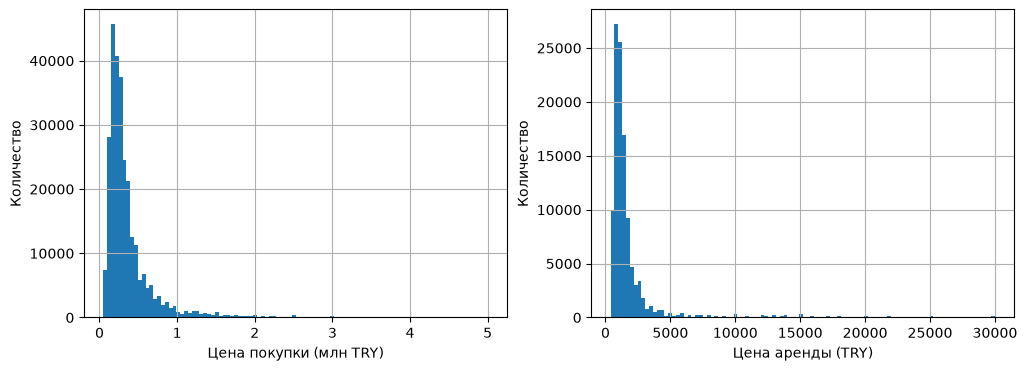

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

(zingat[zingat['listing_type'] == 1]['price_try'] / 1e6).hist(bins=100, ax=ax1)
ax1.set(xlabel='Цена покупки (млн TRY)', ylabel='Количество')

zingat[zingat['listing_type'] == 2]['price_try'].hist(bins=100, ax=ax2)
ax2.set(xlabel='Цена аренды (TRY)', ylabel='Количество')

plt.show()

## 1.3 Визуальный анализ

* Гистограммы распределяют ключевые числовые признаки (площадь, количество
комнат, годовые постройки и т.д.).
* Диаграммы рассеяния (точечная диаграмма) «признак — цена» для основных
признаков.
* Boxplot для восстановления восстановленного по числовому эффекту.
* Тепловая карта корреляций (тепловая карта корреляции) между числовыми внешними
и независимыми переменными.
* Проанализируйте категориальные признаки относительно цены (линейчатая
диаграмма средних цен по категориям — район, тип дома и т.д.).


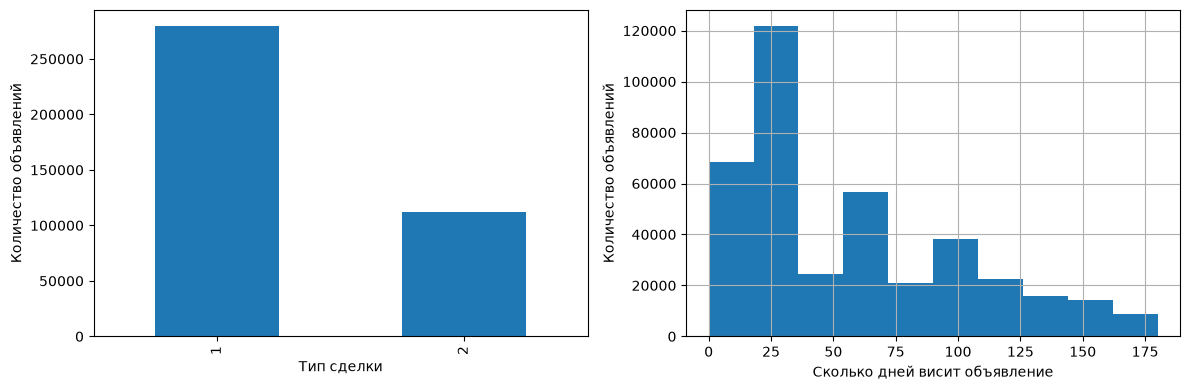

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

zingat['listing_type'].value_counts().plot(kind='bar', ax=ax1)
ax1.set(xlabel='Тип сделки', ylabel='Количество объявлений')

zingat['tom'].hist(ax=ax2)
ax2.set(xlabel='Сколько дней висит объявление', ylabel='Количество объявлений')

plt.tight_layout()
plt.show()

С площадью тоже беда - исправим это сразу.

In [18]:
zingat['size'].skew()

np.float64(88.8544487893467)

In [19]:
percentiles = [0.001, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
zingat['size'].quantile(percentiles)

0.00      1.00
0.01     40.00
0.05     55.00
0.10     69.00
0.25     85.00
0.50    110.00
0.75    140.00
0.90    180.00
0.95    220.00
0.99    354.00
1.00   1500.00
Name: size, dtype: float64

In [20]:
zingat = zingat[zingat['size'].between(25, 500) | zingat['size'].isna()]
zingat['size'].skew()

np.float64(2.0067376462837956)

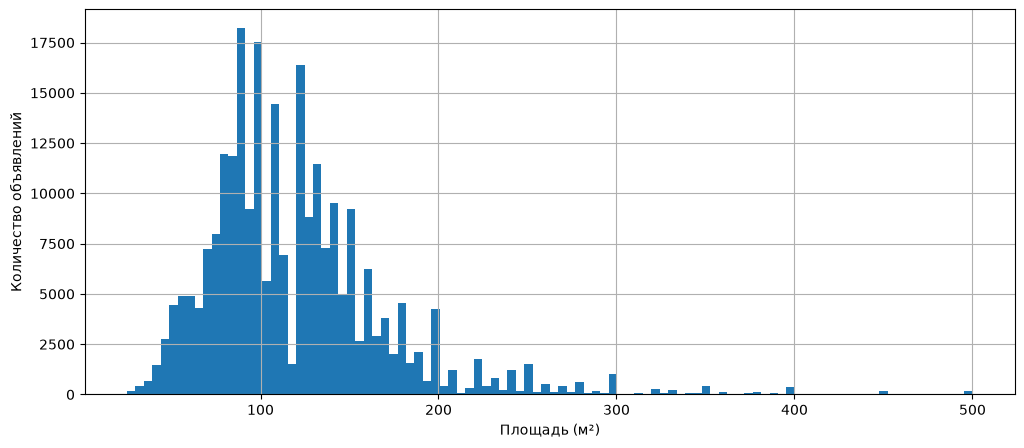

In [21]:
zingat['size'].hist(bins=100, figsize=(12, 5))
plt.xlabel('Площадь (м²)')
plt.ylabel('Количество объявлений')
plt.show()

In [22]:
zingat.info()

<class 'pandas.DataFrame'>
Index: 390574 entries, 0 to 403486
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   sub_type           390574 non-null  str    
 1   start_date         390574 non-null  str    
 2   listing_type       390574 non-null  int64  
 3   tom                390574 non-null  int64  
 4   building_age       365499 non-null  str    
 5   total_floor_count  364186 non-null  str    
 6   floor_no           361366 non-null  str    
 7   room_count         390574 non-null  str    
 8   size               249266 non-null  float64
 9   address            390574 non-null  str    
 10  heating_type       364334 non-null  str    
 11  price_try          390574 non-null  float64
dtypes: float64(2), int64(2), str(8)
memory usage: 64.5 MB


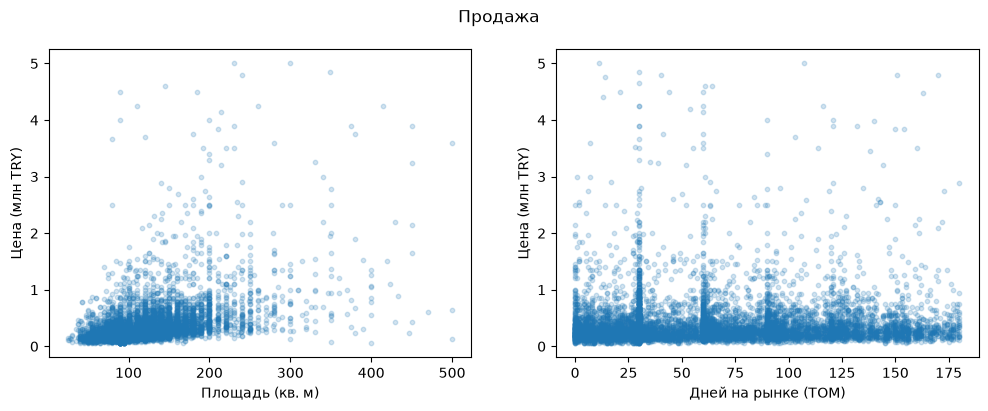

In [23]:
sample = zingat[zingat['listing_type'] == 1].sample(10000, random_state=42)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.scatter(sample['size'], sample['price_try'] / 1e6, alpha=0.2, s=10)
ax1.set(xlabel='Площадь (кв. м)', ylabel='Цена (млн TRY)')

ax2.scatter(sample['tom'], sample['price_try'] / 1e6, alpha=0.2, s=10)
ax2.set(xlabel='Дней на рынке (TOM)', ylabel='Цена (млн TRY)')

plt.suptitle('Продажа')
plt.show()

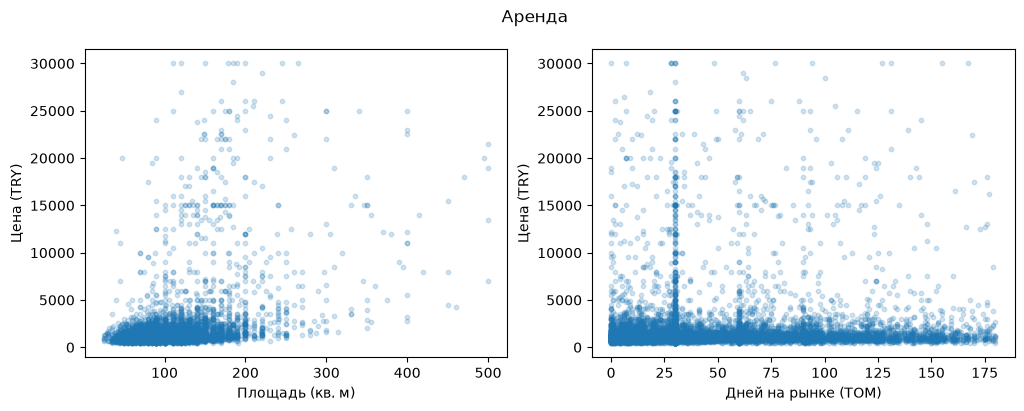

In [24]:
sample = zingat[zingat['listing_type'] == 2].sample(10000, random_state=42)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.scatter(sample['size'], sample['price_try'], alpha=0.2, s=10)
ax1.set(xlabel='Площадь (кв. м)', ylabel='Цена (TRY)')

ax2.scatter(sample['tom'], sample['price_try'], alpha=0.2, s=10)
ax2.set(xlabel='Дней на рынке (TOM)', ylabel='Цена (TRY)')

plt.suptitle('Аренда')
plt.show()

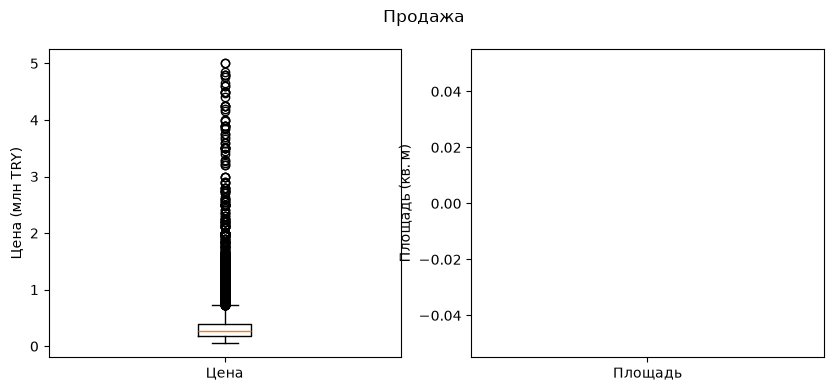

In [25]:
sample = zingat[zingat['listing_type'] == 1].sample(10000, random_state=42)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.boxplot(sample['price_try'] / 1e6)
ax1.set(ylabel='Цена (млн TRY)', xticklabels=['Цена'])

ax2.boxplot(sample['size'])
ax2.set(ylabel='Площадь (кв. м)', xticklabels=['Площадь'])

plt.suptitle('Продажа')
plt.show()

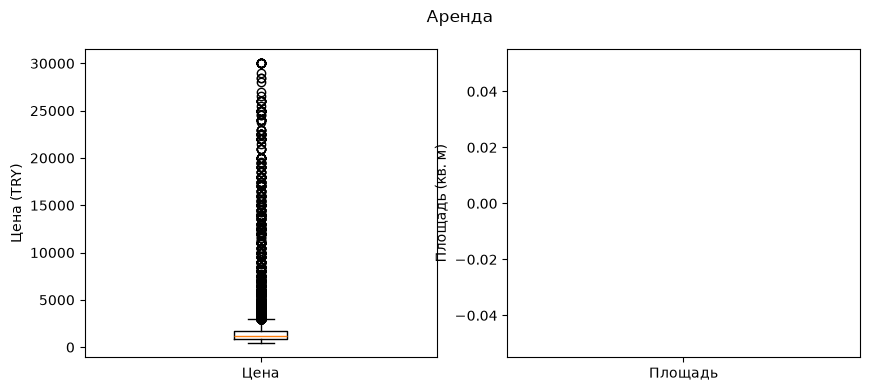

In [26]:
sample = zingat[zingat['listing_type'] == 2].sample(10000, random_state=42)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.boxplot(sample['price_try'])
ax1.set(ylabel='Цена (TRY)', xticklabels=['Цена'])

ax2.boxplot(sample['size'])
ax2.set(ylabel='Площадь (кв. м)', xticklabels=['Площадь'])

plt.suptitle('Аренда')
plt.show()

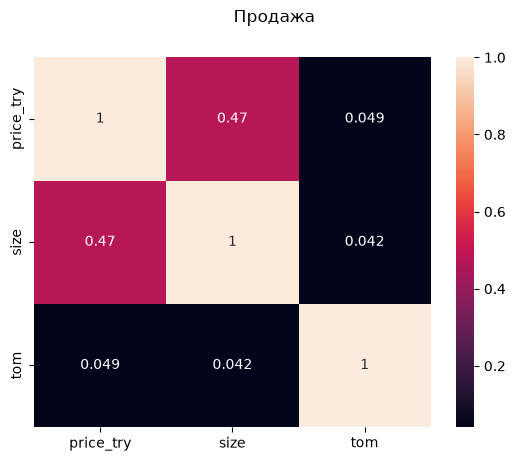

In [27]:
sns.heatmap(zingat[zingat['listing_type'] == 1][['price_try', 'size', 'tom']].corr(), annot=True)
plt.suptitle('Продажа')
plt.show()

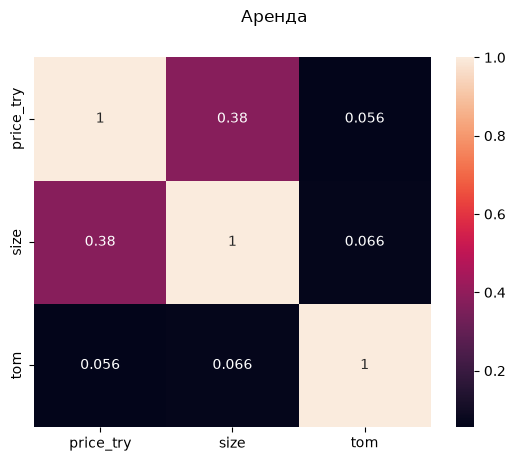

In [28]:
sns.heatmap(zingat[zingat['listing_type'] == 2][['price_try', 'size', 'tom']].corr(), annot=True)
plt.suptitle('Аренда')
plt.show()

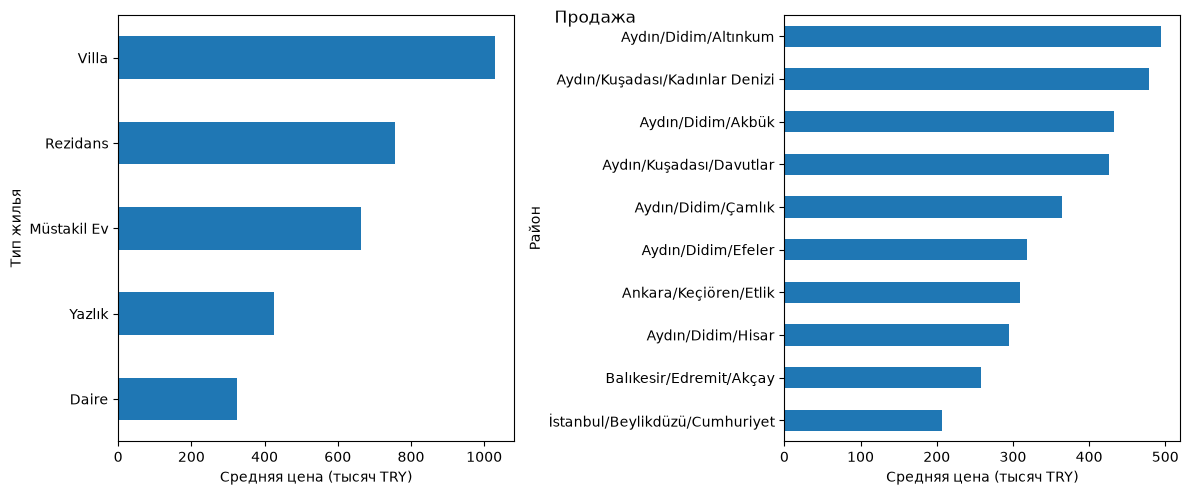

In [29]:
sales = zingat[zingat['listing_type'] == 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

(sales.groupby('sub_type')['price_try'].mean() / 1e3).sort_values().plot(kind='barh', ax=ax1)
ax1.set(xlabel='Средняя цена (тысяч TRY)', ylabel='Тип жилья')

top10 = sales['address'].value_counts().head(10).index
(sales[sales['address'].isin(top10)].groupby('address')['price_try'].mean() / 1e3).sort_values().plot(kind='barh', ax=ax2)
ax2.set(xlabel='Средняя цена (тысяч TRY)', ylabel='Район')

plt.tight_layout()
plt.suptitle('Продажа')
plt.show()

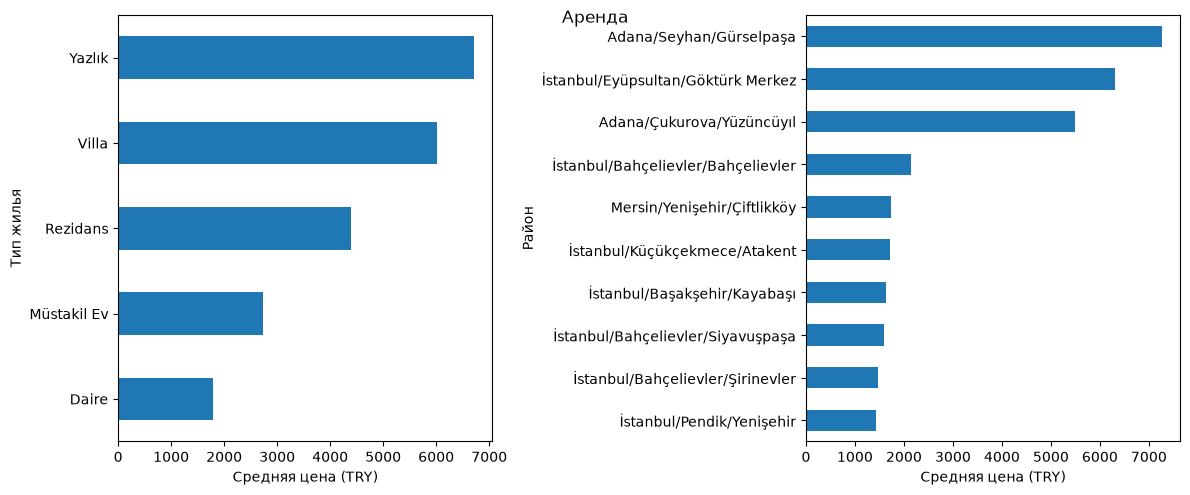

In [30]:
sales = zingat[zingat['listing_type'] == 2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

(sales.groupby('sub_type')['price_try'].mean()).sort_values().plot(kind='barh', ax=ax1)
ax1.set(xlabel='Средняя цена (TRY)', ylabel='Тип жилья')

top10 = sales['address'].value_counts().head(10).index
(sales[sales['address'].isin(top10)].groupby('address')['price_try'].mean()).sort_values().plot(kind='barh', ax=ax2)
ax2.set(xlabel='Средняя цена (TRY)', ylabel='Район')

plt.tight_layout()
plt.suptitle('Аренда')
plt.show()

## 1.4 Анализ пропусков и аномалий

* Таблица/визуализация количества и доли пропущенных результатов по каждому
столбцу.
* Проверка дубликатов записей.
* Проверка логической согласованности данных (например, отрицательная площадь,
нереалистичный год постройки).

In [31]:
pd.DataFrame({
    'Пропуски': zingat.isna().sum(),
    'Доля (%)': (zingat.isna().mean() * 100)
})

,Пропуски,Доля (%)
sub_type,0,0.00
start_date,0,0.00
listing_type,0,0.00
tom,0,0.00
building_age,25075,6.42
total_floor_count,26388,6.76
floor_no,29208,7.48
room_count,0,0.00
size,141308,36.18
address,0,0.00


Так как итоговая цена напрямую зависит от площади, а гадать на кофейной гуще вредно - к сожалению 140к+ записей придётся удалить.

In [32]:
zingat = zingat.dropna(subset=['size'])

In [33]:
print(f"Дубликаты: {zingat.duplicated().sum()}")
zingat = zingat.drop_duplicates()

Дубликаты: 7010


In [34]:
features = ['listing_type', 'sub_type', 'address', 'size', 'room_count', 
            'building_age', 'total_floor_count', 'floor_no', 'heating_type', 'price_try']

print(f"Дубликаты с разными датами размещения: {zingat.duplicated(subset=features).sum()}")
zingat = zingat.drop_duplicates(subset=features, keep='last')

Дубликаты с разными датами размещения: 55780


Проверим напоследок все признаки

In [35]:
zingat['sub_type'].value_counts(dropna=False)

sub_type
Daire          167041
Villa            9021
Müstakil Ev      4013
Rezidans         3662
Yazlık           2739
Name: count, dtype: int64

In [36]:
parsed = pd.to_datetime(zingat['start_date'], format='%m/%d/%y', errors='coerce')
errors = parsed.isna().sum()

print(f"Диапазон от {parsed.min().date()} до {parsed.max().date()}")
print(f"Найдено ошибок: {errors}")

Диапазон от 2018-08-31 до 2019-02-27
Найдено ошибок: 0


In [37]:
zingat['listing_type'].value_counts(dropna=False)

listing_type
1    131137
2     55339
Name: count, dtype: int64

In [38]:
print(f"Количество отрицательных: {(zingat['tom'] < 0).sum()}")
print(f"Максимальное значение: {zingat['tom'].max()}")

Количество отрицательных: 0
Максимальное значение: 180


In [39]:
zingat['building_age'].value_counts(dropna=False)

building_age
0              64737
6-10 arası     24492
11-15 arası    15011
16-20 arası    14800
1               9909
NaN             9347
4               9104
21-25 arası     8874
2               8331
3               7412
5               6350
26-30 arası     5062
31-35 arası     2078
36-40 arası      562
40 ve üzeri      407
Name: count, dtype: int64

In [40]:
zingat['total_floor_count'].value_counts(dropna=False)

total_floor_count
4              39045
3              36170
5              33556
10-20 arası    17495
2              12350
6              11143
NaN             9575
10              6060
7               5942
8               5268
9               4339
20 ve üzeri     3539
1               1994
Name: count, dtype: int64

In [41]:
zingat['floor_no'].value_counts(dropna=False)

floor_no
2               31390
3               25229
1               22365
4               16538
Yüksek Giriş    11261
NaN             10628
5               10045
Müstakil         9272
Bahçe katı       9146
Giriş Katı       5068
6                4810
7                3696
8                2944
Kot 1            2642
Kot 2            2553
9                2279
Kot 3            1917
10               1891
Çatı Katı        1780
Zemin Kat        1648
11               1427
Komple           1238
12               1169
Kot 4            1109
20 ve üzeri       835
13                777
14                668
15                470
En Üst Kat        422
Bodrum Kat        356
16                281
17                226
18                181
Teras Kat         131
19                 82
Asma Kat            2
Name: count, dtype: int64

In [42]:
zingat['room_count'].value_counts(dropna=False)

room_count
3+1     73377
2+1     66276
1+1     18500
4+1     16839
5+1      3527
4+2      2071
5+2      1255
3+2      1198
1+0       997
6+1       814
6+2       503
2+2       371
7+1       190
7+2       109
6+3        62
8+1        59
8+2        55
5+3        47
10+0       45
4+3        37
7+3        26
9+1        25
+          21
9+3        21
9+2        13
8+3        12
8+4        10
10+2        6
9+4         5
9+5         3
10+1        2
Name: count, dtype: int64

In [43]:
zingat = zingat[zingat['room_count'] != '+']

In [44]:
parts_count = zingat['address'].str.split('/').str.len()
print(parts_count.value_counts())

address
3    186450
2         3
1         2
Name: count, dtype: int64


In [45]:
zingat = zingat[parts_count == 3]

In [46]:
zingat['heating_type'].value_counts(dropna=False)

heating_type
Kombi (Doğalgaz)                   95182
Klima                              32530
Merkezi Sistem (Isı Payı Ölçer)    15327
Merkezi Sistem                     10476
NaN                                 9762
Kalorifer (Doğalgaz)                6084
Soba (Kömür)                        3621
Yerden Isıtma                       2968
Yok                                 2846
Kat Kaloriferi                      2566
Kombi (Elektrikli)                  1468
Soba (Doğalgaz)                     1021
Güneş Enerjisi                       768
Kalorifer (Kömür)                    742
Jeotermal                            653
Fancoil                              218
Kalorifer (Akaryakıt)                218
Name: count, dtype: int64

In [47]:
rooms = zingat['room_count'].str.split('+', expand=True).astype(int)
p_m2 = zingat['price_try'] / zingat['size']
f_num = pd.to_numeric(zingat['floor_no'], errors='coerce')
tot_num = pd.to_numeric(zingat['total_floor_count'], errors='coerce')
is_flat = zingat['sub_type'] == 'Daire'
is_villa = zingat['sub_type'].isin(['Villa', 'Müstakil Ev'])
listing_year = pd.to_datetime(zingat['start_date'], format='%m/%d/%y').dt.year
year_built = listing_year - pd.to_numeric(zingat['building_age'], errors='coerce')

anomalies = {
    'Этаж выше общего количества этажей': (f_num > tot_num) | ((zingat['floor_no'] == '20 ve üzeri') & (tot_num < 20)),
    'Виллы выше 4 этажа или в высотках': is_villa & ((f_num > 4) | (tot_num > 4)),
    'Квартиры с этажом Müstakil или Komple': (is_flat | (zingat['sub_type'] == 'Rezidans')) & zingat['floor_no'].isin(['Müstakil', 'Komple']),
    'Резиденции с печью или без тепла': (zingat['sub_type'] == 'Rezidans') & zingat['heating_type'].isin(['Soba (Kömür)', 'Soba (Doğalgaz)', 'Yok']),
    'Продажа: цена < себестоимости бетона или нереалистично высокая': (zingat['listing_type'] == 1) & ((p_m2 < 600) | (is_flat & (p_m2 > 40_000))),
    'Аренда: нереалистичная цена': (zingat['listing_type'] == 2) & ((p_m2 < 4) | (is_flat & (p_m2 > 100))),
    'Меньше 10 м² на комнату': (zingat['size'] / (rooms[0] + rooms[1]).replace(0, 1)) < 10
}

total_bad_mask = pd.Series(False, index=zingat.index)
for desc, mask in anomalies.items():
    cleaned_mask = mask.fillna(False)
    print(f"{desc}: {cleaned_mask.sum()}")
    total_bad_mask |= cleaned_mask

Этаж выше общего количества этажей: 690
Виллы выше 4 этажа или в высотках: 64
Квартиры с этажом Müstakil или Komple: 1208
Резиденции с печью или без тепла: 25
Продажа: цена < себестоимости бетона или нереалистично высокая: 860
Аренда: нереалистичная цена: 943
Меньше 10 м² на комнату: 29


In [48]:
zingat = zingat[~total_bad_mask]

## 1.5 Промежуточные выводы
* Сформулировать 3–5 гипотезу о том, какие признаки сильнее всего влияют на цену,
подтвержденные графиками/корреляциями.

1. Площадь (думаю, это очевидно).
2. Номер этажа комнаты: обычно чем выше - тем дороже.
3. Возможно ещё тип комнаты (sub_type).
4. Тип отопления - электрическое наверное будет дороже.

# Этап 2. Предварительная обработка данных

## 2.1 Работа с пропусками

* Выбрать и обосновать провал для каждого типа пропусков: удаление строк/столбцов,
заполнение медианой/модой, заполнение на основе группировки (например,
медиана по району), использование алгоритмов импутации (KNNImputer и т.п.).

In [49]:
pd.DataFrame({
    'Пропуски': zingat.isna().sum(),
    'Доля (%)': (zingat.isna().mean() * 100)
})

,Пропуски,Доля (%)
sub_type,0,0.00
start_date,0,0.00
listing_type,0,0.00
tom,0,0.00
building_age,9165,5.02
total_floor_count,9422,5.16
floor_no,10460,5.73
room_count,0,0.00
size,0,0.00
address,0,0.00


Нам нужно заполнить все пропуски, потому что мы и так удалили много данных. Если в той же площади попытка угадать - привела бы к шуму, то здесь мы можем дать довольно приблизительные данные.

1. `building_age` - Мы только здесь создадим новую категорию, потому что удалять нельзя, а косвенных признаков для угадывания нет.
2. `total_floor_count` и `floor_no` - Мы можем спокойно заполнить, отталкиваясь друг от друга. Вдобавок, здания обычно строятся кварталами - так что нам поможет ещё и адрес.
3. `heating_type` - В Турции отопление категорически отличается от района к району, группировка по адресам нам в помощь.

## 2.2 Обработка новой

* Выбрать методы обработки: удаление, винсоризация (ограничение по перцентилам),
логарифмирование сильно скошенных признаков.

In [50]:
zingat['building_age'] = zingat['building_age'].fillna('Unknown')

In [51]:
floor_map = {
    '10-20 arası': 15,
    '20 ve üzeri': 20
}
zingat['total_floor_count'] = zingat['total_floor_count'].replace(floor_map).astype(float)

In [52]:
floor_no_map = {
    '20 ve üzeri': 20,
    'Yüksek Giriş': 1,
    'Asma Kat': 1,
    'Müstakil': 1,
    'Komple': 1,
    'Zemin Kat': 0,
    'Giriş Katı': 0,
    'Bahçe katı': 0,
    'Bodrum Kat': -1,
    'Kot 1': -1,
    'Kot 2': -2,
    'Kot 3': -3,
    'Kot 4': -4
}

zingat['floor_no'] = zingat['floor_no'].replace(floor_no_map)
top_floors = ['En Üst Kat', 'Çatı Katı', 'Teras Kat']
top_mask = zingat['floor_no'].isin(top_floors)
zingat.loc[top_mask, 'floor_no'] = zingat.loc[top_mask, 'total_floor_count']
zingat['floor_no'] = pd.to_numeric(zingat['floor_no'], errors='coerce')

In [53]:
group_medians = zingat['total_floor_count'].groupby([zingat['address'], zingat['sub_type']]).transform('median')
global_medians = zingat['total_floor_count'].groupby(zingat['sub_type']).transform('median')
filled_floors = zingat['total_floor_count'].fillna(group_medians).fillna(global_medians)

cur_floor = pd.to_numeric(zingat['floor_no'], errors='coerce')
filled_floors = np.maximum(filled_floors, cur_floor.fillna(1))
zingat['total_floor_count'] = filled_floors.round().astype(int)

In [54]:
is_house = zingat['sub_type'].isin(['Villa', 'Müstakil Ev'])
zingat.loc[is_house & zingat['floor_no'].isna(), 'floor_no'] = 1

group_floor_median = zingat.groupby(['total_floor_count', 'sub_type'])['floor_no'].transform('median')
global_floor_median = zingat.groupby('total_floor_count')['floor_no'].transform('median')
zingat['floor_no'] = zingat['floor_no'].fillna(group_floor_median).fillna(global_floor_median)

zingat['floor_no'] = np.minimum(zingat['floor_no'], zingat['total_floor_count'])
zingat['floor_no'] = zingat['floor_no'].round().astype(int)

In [55]:
mode_by_address = zingat.groupby('address')['heating_type'].transform(lambda s: s.mode().iat[0] if not s.mode().empty else np.nan)

city = zingat['address'].str.split('/').str[0]
mode_by_city = zingat.groupby(city)['heating_type'].transform(lambda s: s.mode().iat[0] if not s.mode().empty else np.nan)

zingat['heating_type'] = zingat['heating_type'].fillna(mode_by_address).fillna(mode_by_city)

In [56]:
pd.DataFrame({
    'Пропуски': zingat.isna().sum(),
    'Доля (%)': (zingat.isna().mean() * 100)
})

,Пропуски,Доля (%)
sub_type,0,0.00
start_date,0,0.00
listing_type,0,0.00
tom,0,0.00
building_age,0,0.00
total_floor_count,0,0.00
floor_no,0,0.00
room_count,0,0.00
size,0,0.00
address,0,0.00


## 2.3 Кодирование категориальных признаков

* One-Hot Encoding для номинальных признаков.
* Порядковое/меточное кодирование для рядовых признаков.
* При большом количестве категорий — целевое/среднее кодирование или
группировка средних категорий в «прочее».

In [57]:
zingat.info()

<class 'pandas.DataFrame'>
Index: 182666 entries, 1 to 403486
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   sub_type           182666 non-null  str    
 1   start_date         182666 non-null  str    
 2   listing_type       182666 non-null  int64  
 3   tom                182666 non-null  int64  
 4   building_age       182666 non-null  str    
 5   total_floor_count  182666 non-null  int64  
 6   floor_no           182666 non-null  int64  
 7   room_count         182666 non-null  str    
 8   size               182666 non-null  float64
 9   address            182666 non-null  str    
 10  heating_type       182666 non-null  str    
 11  price_try          182666 non-null  float64
dtypes: float64(2), int64(4), str(6)
memory usage: 29.4 MB


In [58]:
rooms = zingat['room_count'].str.split('+', expand=True).astype(int)
zingat['bedrooms_count'] = rooms[0]
zingat['living_rooms_count'] = rooms[1]
zingat = zingat.drop(columns=['room_count'])

In [59]:
top_heatings = zingat['heating_type'].value_counts()[lambda x: x >= 2000].index
zingat['heating_type'] = zingat['heating_type'].where(zingat['heating_type'].isin(top_heatings), 'Other')
zingat = pd.get_dummies(zingat, columns=['sub_type', 'heating_type'], drop_first=True, dtype=int)

In [60]:
date_parsed = pd.to_datetime(zingat['start_date'], format='%m/%d/%y')
zingat['start_year'] = date_parsed.dt.year
zingat['start_month'] = date_parsed.dt.month
zingat['start_day'] = date_parsed.dt.day
zingat = zingat.drop(columns=['start_date'])

In [61]:
addr_parts = zingat['address'].str.split('/', expand=True)
zingat['city'] = addr_parts[0]
zingat['district'] = addr_parts[1]
zingat['neighborhood'] = addr_parts[2]
zingat = zingat.drop(columns=['address'])

In [62]:
zingat['is_age_unknown'] = (zingat['building_age'] == 'Unknown').astype(int)
intervals = {
    '6-10 arası': 8,
    '11-15 arası': 13,
    '16-20 arası': 18,
    '21-25 arası': 23,
    '26-30 arası': 28,
    '31-35 arası': 33,
    '36-40 arası': 38,
    '40 ve üzeri': 42
}

zingat['building_age'] = pd.to_numeric(zingat['building_age'].replace(intervals), errors='coerce')
mean_age = zingat['building_age'].mean()
zingat['building_age'] = zingat['building_age'].fillna(round(mean_age)).astype(int)

In [63]:
zingat = zingat.drop(columns=['neighborhood'])

top_cities = zingat['city'].value_counts()[lambda x: x >= 1900].index
zingat['city'] = zingat['city'].where(zingat['city'].isin(top_cities), 'Other')

zingat = pd.get_dummies(zingat, columns=['city'], drop_first=True, dtype=int)

Я пересмотрел датасет заново, и понял, что `tom` и `start_date` не нужны в принципе. Первый не виден покупателю, второй всего лишь полгода.

In [64]:
zingat = zingat.drop(columns=['tom', 'start_year', 'start_month', 'start_day'])

## 2.4 Работа с Feature Engineering

* Создание новых признаков (например, «возраст здания» = текущий год − год
постройки, «цена за м²», «расстояние до центра»).
* Удаление неинформативных/сильно коррелированных между собой признаков
(мультиколлинеарность, VIF).
* При необходимости — уменьшение габаритов.

In [65]:
zingat['total_rooms'] = zingat['bedrooms_count'] + zingat['living_rooms_count']
zingat.drop(columns=['bedrooms_count'], inplace=True)

zingat['area_per_room'] = (zingat['size'] / zingat['total_rooms']).round(2)
zingat['floor_ratio'] = (zingat['floor_no'] / zingat['total_floor_count']).clip(0, 1.0).round(2)

zingat['is_first_floor'] = (zingat['floor_no'] <= 0).astype(int)
zingat['is_top_floor'] = (zingat['floor_no'] == zingat['total_floor_count']).astype(int)

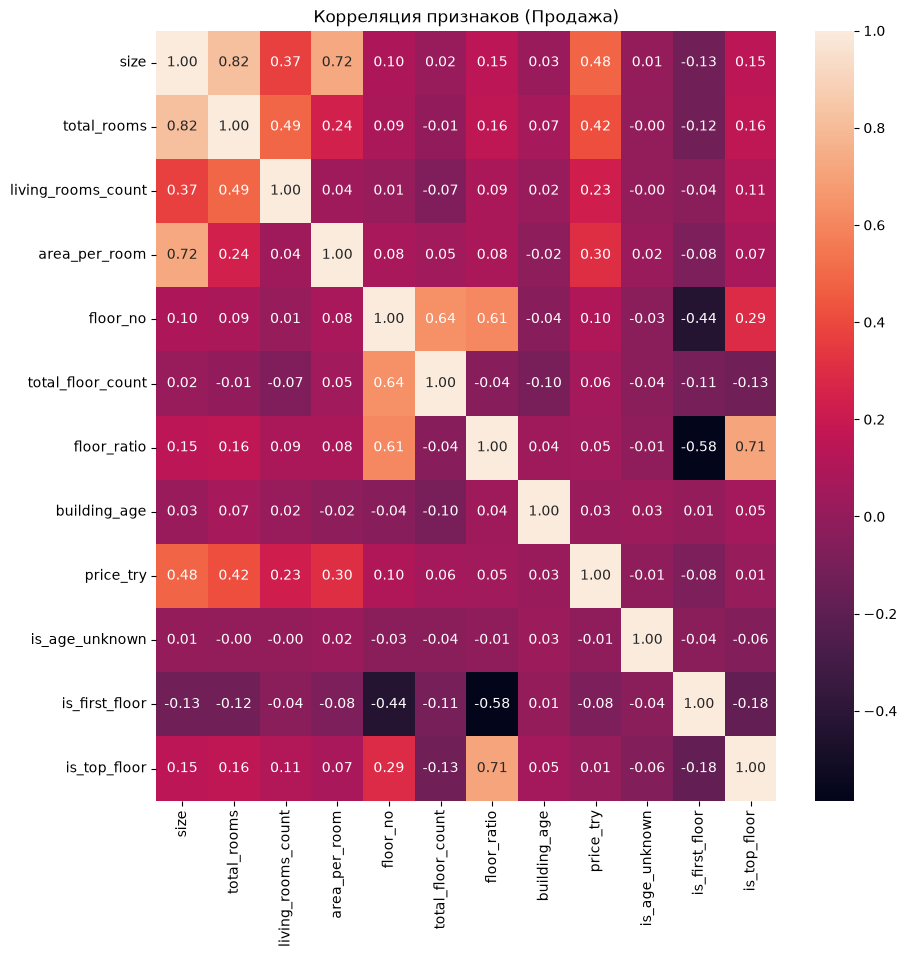

In [66]:
check_cols = ['size', 'total_rooms', 'living_rooms_count', 
    'area_per_room', 'floor_no', 'total_floor_count', 'floor_ratio', 
    'building_age', 'price_try', 'is_age_unknown', 'is_first_floor', 'is_top_floor']

plt.figure(figsize=(10, 10))
sns.heatmap(zingat[zingat['listing_type'] == 1][check_cols].corr(), annot=True, fmt='.2f')
plt.title('Корреляция признаков (Продажа)')
plt.show()

## 2.5 Масштабирование признаков

* Обоснование применения StandardScaler / MinMaxScaler / RobustScaler в зависимости
от выбранных моделей (для линейных моделей — обязательно, для деревьев — не
обязательно).

Так как я буду использовать следующие модели:
1. Регрессор дерева решений.
2. Случайный лесной регрессор.
3. LightGBM

   ... им масштабирование не нужно.

## 2.6 Разбиение данных

* Разделение на train/validation/test (например, 70/15/15 или train/test 80/20 с кроссвалидацией).
* Фиксация случайного_состояния для воспроизводимости.
* Проверка на утечку данных (утечку данных): все конвертируются (скалер, кодер)
обучаются только на train.


In [67]:
z_sale = zingat[zingat['listing_type'] == 1].drop(columns=['listing_type']).reset_index(drop=True)
z_rental = zingat[zingat['listing_type'] == 2].drop(columns=['listing_type']).reset_index(drop=True)

In [68]:
X_sale = z_sale.drop(columns=['price_try'])
y_sale = z_sale['price_try']

X_rental = z_rental.drop(columns=['price_try'])
y_rental = z_rental['price_try']

In [69]:
X_train_s, X_temp_s, y_train_s, y_temp_s = train_test_split(X_sale, y_sale, test_size=0.30, random_state=42)
X_val_s, X_test_s, y_val_s, y_test_s = train_test_split(X_temp_s, y_temp_s, test_size=0.50, random_state=42)

X_train_s, X_val_s, X_test_s = X_train_s.copy(), X_val_s.copy(), X_test_s.copy()

In [70]:
X_train_r, X_temp_r, y_train_r, y_temp_r = train_test_split(X_rental, y_rental, test_size=0.30, random_state=42)
X_val_r, X_test_r, y_val_r, y_test_r = train_test_split(X_temp_r, y_temp_r, test_size=0.50, random_state=42)

X_train_r, X_val_r, X_test_r = X_train_r.copy(), X_val_r.copy(), X_test_r.copy()

In [71]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [72]:
te_sale = TargetEncoder(smooth='auto', cv=cv)

X_train_s['district'] = te_sale.fit_transform(X_train_s[['district']], y_train_s)

X_val_s['district'] = te_sale.transform(X_val_s[['district']])
X_test_s['district'] = te_sale.transform(X_test_s[['district']])

In [73]:
te_rental = TargetEncoder(smooth='auto', cv=cv)

X_train_r['district'] = te_rental.fit_transform(X_train_r[['district']], y_train_r)

X_val_r['district'] = te_rental.transform(X_val_r[['district']])
X_test_r['district'] = te_rental.transform(X_test_r[['district']])

In [74]:
print(f"Продажа\nTrain: {X_train_s.shape}, Val: {X_val_s.shape}, Test: {X_test_s.shape}\n")
print(f"Аренда\nTrain: {X_train_r.shape}, Val: {X_val_r.shape}, Test: {X_test_r.shape}")

Продажа
Train: (90175, 44), Val: (19323, 44), Test: (19324, 44)

Аренда
Train: (37690, 44), Val: (8077, 44), Test: (8077, 44)


# Этап 3. Построение модели регрессии

## 3.1 Требование: не менее 3 разных моделей

Рекомендуемый набор (выбрать минимум 3, желательно разной природы):
1. Линейная модель — Линейная регрессия/Ридж/Лассо/ElasticNet.
2. Модель на основе деревьев (одиночная) — Регрессор дерева решений.
3. Ансамблевая модель (бэггинг) — Случайный лесной регрессор.
4. Ансамблевая модель (бустинг) — Gradient Boosting/XGBoost/LightGBM/CatBoost.
5. Опционально — КНН Регрессор, СВР, нейронная сеть (MLPRegressor).

In [75]:
models_sale = {
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'LightGBM': LGBMRegressor(random_state=42, verbose=-1)
}

models_rental = {
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'LightGBM': LGBMRegressor(random_state=42, verbose=-1)
}

## 3.2 Обучение и выбор гиперпараметров

* Для каждой модели — базовая версия с параметрами по умолчанию.
* Подбор гиперпараметров: GridSearchCV / RandomizedSearchCV / Optuna с кроссвалидацией на train.
* Фиксация лучших параметров для каждой модели.

In [76]:
print("Продажа")
for name, model in models_sale.items():
    print(f"Обучение {name}")
    model.fit(X_train_s, y_train_s)

print("\nАренда")
for name, model in models_rental.items():
    print(f"Обучение {name}")
    model.fit(X_train_r, y_train_r)

Продажа
Обучение Decision Tree
Обучение Random Forest
Обучение LightGBM

Аренда
Обучение Decision Tree
Обучение Random Forest
Обучение LightGBM


In [77]:
param_grids = {
    'Decision Tree': {
        'max_depth': [5, 10, 15, 20, None],
        'min_samples_split': [2, 5, 10, 20],
        'min_samples_leaf': [1, 2, 5, 10]
    },
    'Random Forest': {
        'n_estimators': [50, 100],
        'max_depth': [10, 15, 20, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },
    'LightGBM': {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.03, 0.05, 0.1],
        'num_leaves': [31, 63, 127],
        'max_depth': [-1, 10, 15]
    }
}

In [78]:
best_models_sale = {}
best_params_sale = {}

for name in models_sale.keys():
    print(f"\nПоиск {name}")
    
    if name == 'Decision Tree':
        base_estimator = DecisionTreeRegressor(random_state=42)
    elif name == 'Random Forest':
        base_estimator = RandomForestRegressor(random_state=42, n_jobs=-1)
    elif name == 'LightGBM':
        base_estimator = LGBMRegressor(random_state=42, verbose=-1)
        
    search = RandomizedSearchCV(estimator=base_estimator, param_distributions=param_grids[name],
                                n_iter=6, cv=3, scoring='neg_mean_absolute_error', random_state=42, n_jobs=-1)
    search.fit(X_train_s, y_train_s)
    
    best_models_sale[name] = search.best_estimator_
    best_params_sale[name] = search.best_params_
    
    print(f"Параметры {name}:")
    print(search.best_params_)


Поиск Decision Tree
Параметры Decision Tree:
{'min_samples_split': 10, 'min_samples_leaf': 10, 'max_depth': 10}

Поиск Random Forest
Параметры Random Forest:
{'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}

Поиск LightGBM
Параметры LightGBM:
{'num_leaves': 63, 'n_estimators': 200, 'max_depth': -1, 'learning_rate': 0.05}


In [79]:
best_models_rental = {}
best_params_rental = {}

for name in models_rental.keys():
    print(f"\nПоиск {name}")
    
    if name == 'Decision Tree':
        base_estimator = DecisionTreeRegressor(random_state=42)
    elif name == 'Random Forest':
        base_estimator = RandomForestRegressor(random_state=42, n_jobs=-1)
    elif name == 'LightGBM':
        base_estimator = LGBMRegressor(random_state=42, verbose=-1)
        
    search = RandomizedSearchCV(estimator=base_estimator, param_distributions=param_grids[name],
                                n_iter=6, cv=3, scoring='neg_mean_absolute_error', random_state=42, n_jobs=-1)
    search.fit(X_train_r, y_train_r)
    
    best_models_rental[name] = search.best_estimator_
    best_params_rental[name] = search.best_params_
    
    print(f"Параметры {name}:")
    print(search.best_params_)


Поиск Decision Tree
Параметры Decision Tree:
{'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 10}

Поиск Random Forest
Параметры Random Forest:
{'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}

Поиск LightGBM
Параметры LightGBM:
{'num_leaves': 63, 'n_estimators': 200, 'max_depth': -1, 'learning_rate': 0.05}


## 3.3 Метрики качества

Рассчитать для каждой модели по валидации/тестированию не менее 3–4 метрик:
* MAE (средняя абсолютная ошибка) — средняя абсолютная ошибка в единицах цен.
* RMSE (среднеквадратическая ошибка) — чувствительна к большим ошибкам.
* MAPE (Mean Absolute Percentage Error) — ошибка в процентах, удобна для обозначения.
* R² (коэффициент детерминации) — доля объяснённой дисперсии.
* Опционально: скорректированный R², медианная абсолютная ошибка.

In [80]:
def get_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    r2 = r2_score(y_true, y_pred)
    return {
        'MAE (TRY)': mae,
        'RMSE (TRY)': rmse,
        'MAPE (%)': mape,
        'R2': r2
    }

In [81]:
results_sale = []

for name, model in models_sale.items():
    preds = model.predict(X_test_s)
    m = get_metrics(y_test_s, preds)
    m['Модель'] = f"{name} (Базовые параметры)"
    results_sale.append(m)

for name, model in best_models_sale.items():
    preds = model.predict(X_test_s)
    m = get_metrics(y_test_s, preds)
    m['Модель'] = f"{name} (Лучшие параметры)"
    results_sale.append(m)

metrics_sale_df = pd.DataFrame(results_sale).set_index('Модель')
metrics_sale_df = metrics_sale_df.sort_values(by='R2', ascending=False)
metrics_sale_df

,MAE (TRY),RMSE (TRY),MAPE (%),R2
Модель,,,,
LightGBM (Лучшие параметры),111128.88,238461.18,28.45,0.69
LightGBM (Базовые параметры),113155.28,238983.26,29.32,0.69
Random Forest (Лучшие параметры),108487.87,241553.29,26.67,0.68
Random Forest (Базовые параметры),109513.14,242322.66,27.28,0.68
Decision Tree (Лучшие параметры),123644.43,264680.69,31.66,0.62
Decision Tree (Базовые параметры),145204.53,342990.14,35.90,0.36


In [82]:
results_rental = []

for name, model in models_rental.items():
    preds = model.predict(X_test_r)
    m = get_metrics(y_test_r, preds)
    m['Модель'] = f"{name} (Базовые параметры)"
    results_rental.append(m)

for name, model in best_models_rental.items():
    preds = model.predict(X_test_r)
    m = get_metrics(y_test_r, preds)
    m['Модель'] = f"{name} (Лучшие параметры)"
    results_rental.append(m)

metrics_rental_df = pd.DataFrame(results_rental).set_index('Модель')
metrics_rental_df = metrics_rental_df.sort_values(by='R2', ascending=False)
metrics_rental_df

,MAE (TRY),RMSE (TRY),MAPE (%),R2
Модель,,,,
LightGBM (Базовые параметры),602.51,1562.86,31.96,0.55
LightGBM (Лучшие параметры),588.42,1569.02,30.82,0.55
Random Forest (Лучшие параметры),577.43,1598.07,29.81,0.53
Random Forest (Базовые параметры),584.43,1608.47,30.70,0.52
Decision Tree (Лучшие параметры),642.02,1756.07,34.56,0.43
Decision Tree (Базовые параметры),741.92,2129.85,39.65,0.16


## 3.4 Сравнение моделей

* Сведите все метрики в единую сравнительную таблицу.
* Постройте график сравнения моделей по метрикам (столбчатая диаграмма).
* Постройте графики «предсказание против факта» (разброс) и график элементов (остатков) для лучшей модели.
* Проанализировать результаты (важность признаков) для деревянных моделей/коэффициенты для линейных.

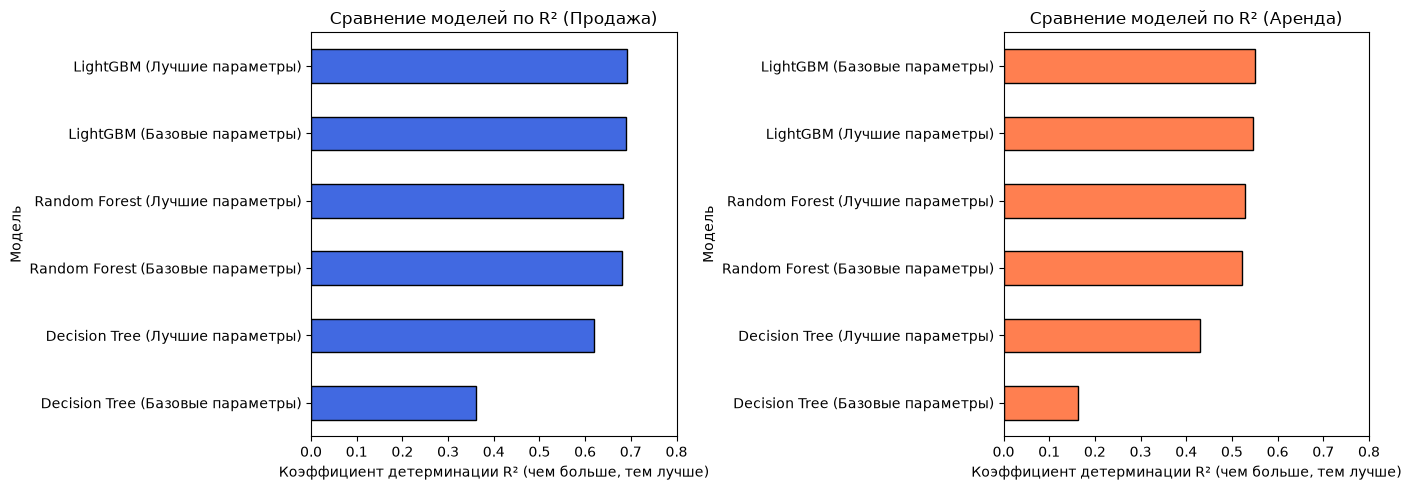

In [83]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

metrics_sale_df['R2'].sort_values().plot(kind='barh', ax=ax1, color='royalblue', edgecolor='black')
ax1.set_title('Сравнение моделей по R² (Продажа)')
ax1.set_xlabel('Коэффициент детерминации R² (чем больше, тем лучше)')
ax1.set_xlim(0, 0.8)

metrics_rental_df['R2'].sort_values().plot(kind='barh', ax=ax2, color='coral', edgecolor='black')
ax2.set_title('Сравнение моделей по R² (Аренда)')
ax2.set_xlabel('Коэффициент детерминации R² (чем больше, тем лучше)')
ax2.set_xlim(0, 0.8)

plt.tight_layout()
plt.show()

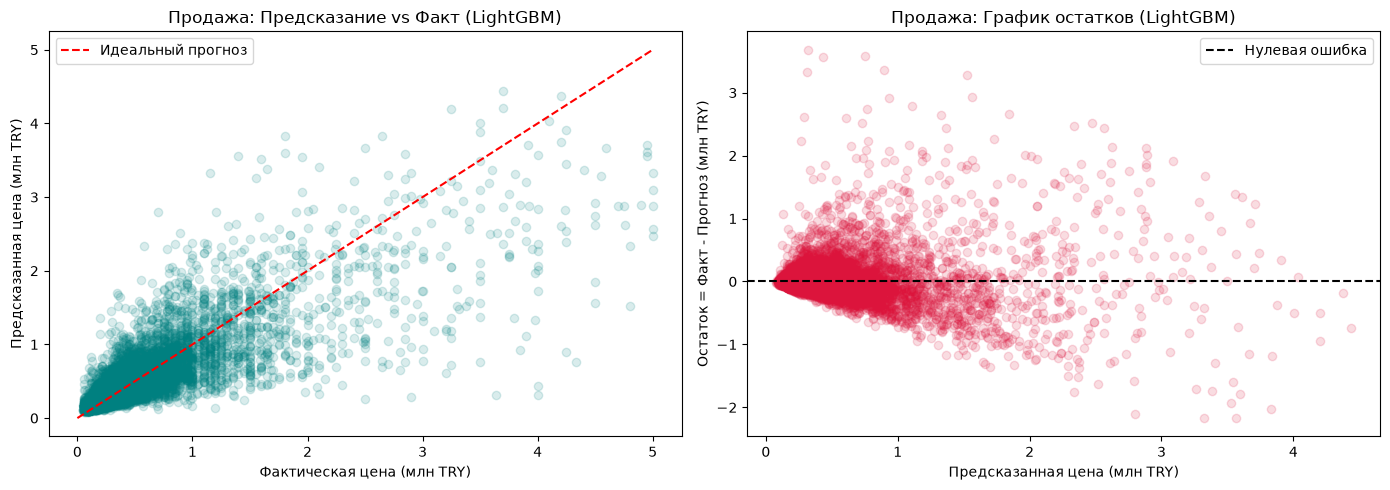

In [84]:
best_lgb_s = best_models_sale['LightGBM']
preds_s = best_lgb_s.predict(X_test_s)
residuals_s = y_test_s - preds_s

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(y_test_s / 1e6, preds_s / 1e6, alpha=0.15, color='teal')
max_val = max(y_test_s.max(), preds_s.max()) / 1e6
ax1.plot([0, max_val], [0, max_val], color='red', linestyle='--', label='Идеальный прогноз')
ax1.set_title('Продажа: Предсказание vs Факт (LightGBM)')
ax1.set_xlabel('Фактическая цена (млн TRY)')
ax1.set_ylabel('Предсказанная цена (млн TRY)')
ax1.legend()

ax2.scatter(preds_s / 1e6, residuals_s / 1e6, alpha=0.15, color='crimson')
ax2.axhline(0, color='black', linestyle='--', label='Нулевая ошибка')
ax2.set_title('Продажа: График остатков (LightGBM)')
ax2.set_xlabel('Предсказанная цена (млн TRY)')
ax2.set_ylabel('Остаток = Факт - Прогноз (млн TRY)')
ax2.legend()

plt.tight_layout()
plt.show()

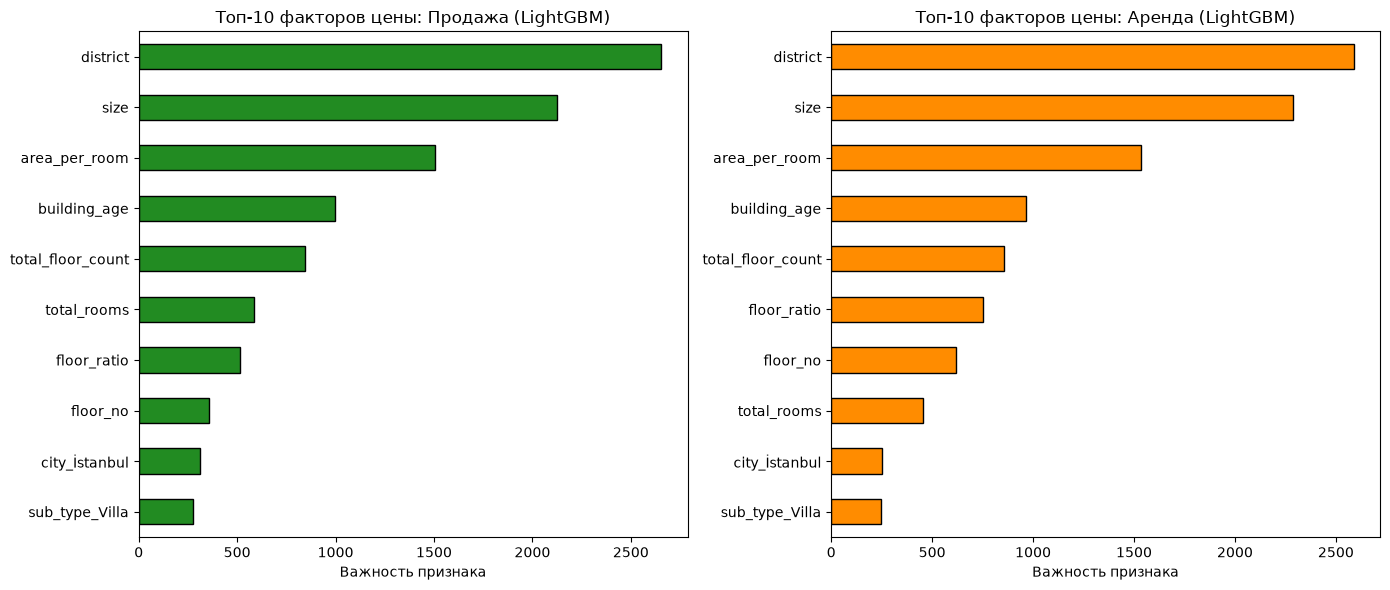

In [85]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

imp_sale = pd.Series(best_models_sale['LightGBM'].feature_importances_, index=X_train_s.columns)
imp_sale.nlargest(10).sort_values().plot(kind='barh', ax=ax1, color='forestgreen', edgecolor='black')
ax1.set_title('Топ-10 факторов цены: Продажа (LightGBM)')
ax1.set_xlabel('Важность признака')

imp_rental = pd.Series(best_models_rental['LightGBM'].feature_importances_, index=X_train_r.columns)
imp_rental.nlargest(10).sort_values().plot(kind='barh', ax=ax2, color='darkorange', edgecolor='black')
ax2.set_title('Топ-10 факторов цены: Аренда (LightGBM)')
ax2.set_xlabel('Важность признака')

plt.tight_layout()
plt.show()

## 3.5 Выбор финальной модели

* Обосновать выбор лучшей модели для дальнейшего использования в приложении: не только по метрикам, но и с учетом скорости вывода, интерпретируемости, устойчивости к переобучению.
* Сохраните сохраненную модель и все препроцессоры (скалер, кодер) в файле (pickle/joblib) для использования в приложении.

In [86]:
sale_bundle = {
    'model': best_models_sale['LightGBM'],
    'target_encoder': te_sale,
    'feature_names': list(X_train_s.columns)
}

rental_bundle = {
    'model': best_models_rental['LightGBM'],
    'target_encoder': te_rental,
    'feature_names': list(X_train_r.columns)
}

joblib.dump(sale_bundle, 'model_sale.joblib')
joblib.dump(rental_bundle, 'model_rental.joblib')

['model_rental.joblib']

In [87]:
loaded_sale = joblib.load('model_sale.joblib')

sample_obj = X_test_s.iloc[[0]]
test_prediction = loaded_sale['model'].predict(sample_obj)[0]
true_value = y_test_s.iloc[0]

print(f"Реальная цена: {true_value:,.2f} TRY")
print(f"Прогноз из файла: {test_prediction:,.2f} TRY")
print(f"Количество признаков: {len(loaded_sale['feature_names'])}")

Реальная цена: 125,000.00 TRY
Прогноз из файла: 238,667.94 TRY
Количество признаков: 44


In [88]:
z_sale.info()

<class 'pandas.DataFrame'>
RangeIndex: 128822 entries, 0 to 128821
Data columns (total 45 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   building_age                                  128822 non-null  int64  
 1   total_floor_count                             128822 non-null  int64  
 2   floor_no                                      128822 non-null  int64  
 3   size                                          128822 non-null  float64
 4   price_try                                     128822 non-null  float64
 5   living_rooms_count                            128822 non-null  int64  
 6   sub_type_Müstakil Ev                          128822 non-null  int64  
 7   sub_type_Rezidans                             128822 non-null  int64  
 8   sub_type_Villa                                128822 non-null  int64  
 9   sub_type_Yazlık                               128822 non-nu